In [61]:
import pandas as pd
import numpy as np
from scipy import stats
import ast

from sklearn import metrics
from sklearn.metrics import roc_curve, roc_auc_score
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import matthews_corrcoef

import matplotlib.pyplot as plt


In [2]:
def classification_metrics(target, pred):
    tn, fp, fn, tp = metrics.confusion_matrix(target, pred).ravel()
    acc = (tp + tn) / (tn + fp + fn + tp)
    sen = tp / (tp + fn)
    spc = tn / (tn + fp)
    prc = tp / (tp + fp)
    mcc = ((tp * tn) - (fp * fn)) / ((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn) + .00000001) ** 0.5
    return acc.item(), sen.item(), spc.item(), prc.item(), mcc.item()

# acc, sen, spc, prc, mcc = classification_metrics(y_test, y_hat)

In [3]:
df_dock = pd.read_csv("data/GlideDocking_20250616_PAH_0-20000_hitlist.csv")
df_dock = df_dock.iloc[1:][['Title', 'Energy-1', 'docking score', 'glide emodel', 'glide gscore']]
df_dock['ID'] = [i.split('_')[0] for i in df_dock['Title']]
df_dock = df_dock.groupby('ID').aggregate('min')
# df_dock['ID'] = df_dock.index
df_dock.head()

/var/folders/g9/1n3d85nn2d14mq2r60k26ddc0000gn/T/ipykernel_49295/2029463181.py:1: DtypeWarning: Columns (5,50,51,52,53,54,55,56,57,58,59,60,61,62,63,64,65,66,67,68,69,70,71,72,73,74,75,76,77,78,79,80,81,82,83,84,85,86,87,88,89,90,91,92,93,94,95,96,97,98,99,100,101,102,103,104) have mixed types. Specify dtype option on import or set low_memory=False.
  df_dock = pd.read_csv("data/GlideDocking_20250616_PAH_0-20000_hitlist.csv")


,Title,Energy-1,docking score,glide emodel,glide gscore
ID,,,,,
BH4,BH4,NaN,-6.054,-47.570,-6.054
CSCS00000001360,CSCS00000001360_0,15.275,-4.923,-31.623,-4.923
CSCS00000002301,CSCS00000002301_0,19.412,-4.873,-29.669,-4.873
CSCS00000005658,CSCS00000005658_0,-4.573,-4.924,-28.408,-4.924
CSCS00000007163,CSCS00000007163_0,-1.632,-4.963,-31.181,-4.963


In [4]:
control_ligands = [i for i in df_dock.index if i.find('CSCS') == -1]
control_affinity = df_dock.loc[df_dock.index.isin(control_ligands), 'docking score'].tolist()
control_ligands, control_affinity

(['BH4', 'Phe', 'Sepiapterin', 'UCR102', 'UCR243'],
 [-6.054, -4.498, -3.793, -6.435, -6.342])

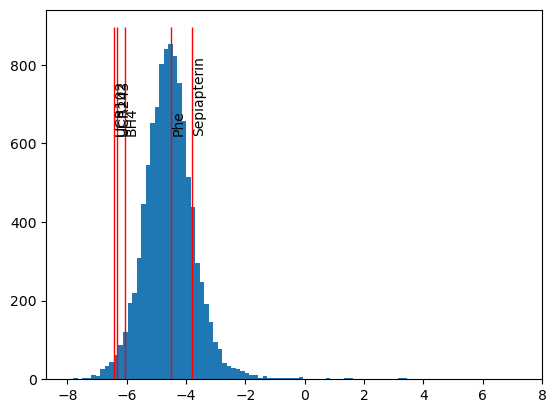

In [5]:
plt.hist(df_dock['docking score'], 100);
y_max = plt.ylim()[1]
plt.vlines(control_affinity, ymin=0, ymax=y_max, color='red', linewidth = 1);
for lig, aff in zip(control_ligands, control_affinity):
    plt.text(x=aff, y=y_max*.7, s=lig, rotation = 90, size = 10)

In [169]:
## Add Binding_validated_by_TSA
conversion_dict = {
    ('strong_evidence', 'strong_evidence', 'strong_evidence') : 'strong_evidence',
    ('strong_evidence', 'strong_evidence', 'weak_evidence')   : 'strong_evidence',
    ('strong_evidence', 'strong_evidence', 'no_evidence')     : 'strong_evidence',
    ('strong_evidence', 'weak_evidence',   'strong_evidence') : 'strong_evidence',
    ('strong_evidence', 'weak_evidence',   'weak_evidence')   : 'strong_evidence',
    ('strong_evidence', 'weak_evidence',   'no_evidence')     : 'strong_evidence',
    ('strong_evidence', 'no_evidence',     'strong_evidence') : 'strong_evidence',
    ('strong_evidence', 'no_evidence',     'weak_evidence')   : 'strong_evidence',
    ('strong_evidence', 'no_evidence',     'no_evidence')     : 'weak_evidence',
    ('weak_evidence',   'strong_evidence', 'strong_evidence') : 'weak_evidence',
    ('weak_evidence',   'strong_evidence', 'weak_evidence')   : 'weak_evidence',
    ('weak_evidence',   'strong_evidence', 'no_evidence')     : 'strong_evidence',
    ('weak_evidence',   'weak_evidence',   'strong_evidence') : 'weak_evidence',
    ('weak_evidence',   'weak_evidence',   'weak_evidence')   : 'weak_evidence',
    ('weak_evidence',   'weak_evidence',   'no_evidence')     : 'weak_evidence',
    ('weak_evidence',   'no_evidence',     'strong_evidence') : 'strong_evidence',
    ('weak_evidence',   'no_evidence',     'weak_evidence')   : 'weak_evidence',
    ('weak_evidence',   'no_evidence',     'no_evidence')     : 'weak_evidence',
    ('no_evidence',     'strong_evidence', 'strong_evidence') : 'weak_evidence',
    ('no_evidence',     'strong_evidence', 'weak_evidence')   : 'weak_evidence',
    ('no_evidence',     'strong_evidence', 'no_evidence')     : 'weak_evidence',
    ('no_evidence',     'weak_evidence',   'strong_evidence') : 'weak_evidence',
    ('no_evidence',     'weak_evidence',   'weak_evidence')   : 'weak_evidence',
    ('no_evidence',     'weak_evidence',   'no_evidence')     : 'weak_evidence',
    ('no_evidence',     'no_evidence',     'strong_evidence') : 'weak_evidence',
    ('no_evidence',     'no_evidence',     'weak_evidence')   : 'weak_evidence',
    ('no_evidence',     'no_evidence',     'no_evidence')     : 'no_evidence',
}

In [235]:
col_bind = 'Binding_validated_by_TSA'
col_bind = 'new'

# df_expr = pd.read_csv("data/PO_norm_outlier_removed.csv")
df_expr = pd.read_csv("data/PO_norm_analysed_16may.csv")

df_expr['bind_tsa'] = df_expr['bind_tsa'].apply(ast.literal_eval)
df_expr[col_bind] = df_expr['bind_tsa'].map(conversion_dict)

df_expr = df_expr[['ID', 'Protein', col_bind]]
df_expr = df_expr.loc[~df_expr['ID'].isin(['BH4', 'UCR243', 'UCR102'])]
df_expr.head()

/var/folders/g9/1n3d85nn2d14mq2r60k26ddc0000gn/T/ipykernel_49295/1902401097.py:5: DtypeWarning: Columns (24) have mixed types. Specify dtype option on import or set low_memory=False.
  df_expr = pd.read_csv("data/PO_norm_analysed_16may.csv")


,ID,Protein,new
2,CSCS00104537142,PAH-WT,weak_evidence
3,CSCS00133135693,PAH-WT,no_evidence
4,CSCS00093835758,PAH-WT,weak_evidence
5,CSCS00133112516,PAH-WT,weak_evidence
6,CSCS00133028662,PAH-WT,strong_evidence


In [236]:
df_merge = pd.merge(df_expr, df_dock, on = 'ID')
df_merge = df_merge.loc[df_merge[col_bind] != 'weak_evidence']
df_merge.head()

,ID,Protein,new,Title,Energy-1,docking score,glide emodel,glide gscore
2,CSCS00027634803,PAH-WT,strong_evidence,CSCS00027634803_0,-237.582,-4.303,-45.180,-4.303
3,CSCS00133044588,PAH-WT,strong_evidence,CSCS00133044588,83.672,-5.433,-50.061,-5.433
4,CSCS00028307373,PAH-WT,strong_evidence,CSCS00028307373_0,84.334,0.936,-21.704,0.936
5,CSCS00133146767,PAH-WT,strong_evidence,CSCS00133146767_0,96.021,-5.391,-44.369,-5.391
7,CSCS00133043343,PAH-WT,strong_evidence,CSCS00133043343_0,-55.436,-5.177,-61.131,-5.178


In [237]:
tab = df_merge.groupby(col_bind).count()['ID']
tab

new
no_evidence        10658
strong_evidence      973
Name: ID, dtype: int64

In [238]:
tab['strong_evidence'] / tab.sum()   # prc best

np.float64(0.08365574757114608)

In [239]:
prot = 'PAH-WT'
percentage = 8

df_merge_prot = df_merge.loc[df_merge['Protein'] == prot]
target = df_merge_prot[col_bind] == 'strong_evidence'
score = df_merge_prot['docking score']
threshold = np.percentile(score, percentage)
pred = score <= threshold

In [240]:
# percentage * len(pred) / 100, (pred).sum().item(), len(pred), (target).sum().item()

In [241]:
top_k = (pred).sum().item()
total_pos = (target).sum().item()
sen_best = top_k / total_pos
sen_best

0.5641379310344827

In [242]:
acc, sen, spc, prc, mcc = classification_metrics(target, pred)
acc, sen, spc, prc, mcc

(0.8035609469771082,
 0.0896551724137931,
 0.9215686274509803,
 0.15892420537897312,
 0.01443245674623365)

0.6802379933495362

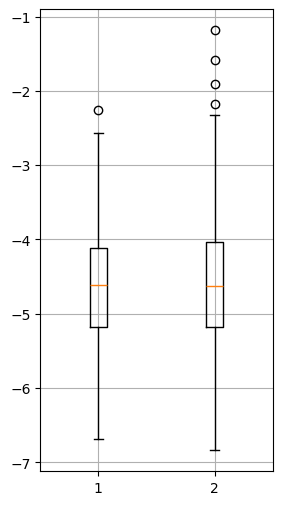

In [214]:
plt.figure(figsize=(3, 6))
p_val = stats.ttest_ind(score[target], 
                        score[~target]
                          ).pvalue.item()
plt.boxplot([score[target], score[~target]]);
plt.grid()
p_val

In [254]:
df_expr = pd.read_csv("data/PO_norm_analysed_16may.csv")
df_expr.loc[df_expr['Protein'] != 'failed'].groupby('Binding_validated_by_TSA').count()['ID']

/var/folders/g9/1n3d85nn2d14mq2r60k26ddc0000gn/T/ipykernel_49295/3759153234.py:1: DtypeWarning: Columns (24) have mixed types. Specify dtype option on import or set low_memory=False.
  df_expr = pd.read_csv("data/PO_norm_analysed_16may.csv")


Binding_validated_by_TSA
no_evidence        71100
strong_evidence    12388
weak_evidence      79312
Name: ID, dtype: int64

In [ ]:
df_expr

In [249]:
71229 / 12410

5.739645447219984

In [253]:
df_expr = pd.read_csv("data/PO_norm_analysed_11may.csv")
df_expr.loc[df_expr['Protein'] != 'failed'].groupby('Binding_validated_by_TSA').count()['ID']

/var/folders/g9/1n3d85nn2d14mq2r60k26ddc0000gn/T/ipykernel_49295/4216258461.py:1: DtypeWarning: Columns (24) have mixed types. Specify dtype option on import or set low_memory=False.
  df_expr = pd.read_csv("data/PO_norm_analysed_11may.csv")


Binding_validated_by_TSA
no_evidence        71100
strong_evidence     6687
weak_evidence      85013
Name: ID, dtype: int64

In [248]:
71229 / 6694 

10.640723035554227